# CICEVSE2024 - Preliminary Results for the AI-SOC Capstone
**What this notebook does** (run top to bottom; every cell prints what it found):
1. Cleans each source (incl. the host-file label repair found in the audit)
2. Plots class distributions (dataset justification evidence)
3. Checks whether the three sources can be aligned in time
4. Trains baselines (Dummy -> Logistic Regression -> Random Forest) with a **blocked, leakage-aware split**
5. Runs a separate Isolation Forest anomaly experiment on Power
6. Writes a sample structured alert (the interface to your agentic layer)

All outputs go to the `preliminary_results/` folder next to this notebook.
Nothing here is a final result: it is a first, honest baseline.

## 0. Configuration

In [4]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, average_precision_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40)

SEED = 42
DATA_DIR = Path(os.environ.get("EV_DATA_DIR", r"E:\Dataset\extracted"))
RESULTS = Path("preliminary_results")
RESULTS.mkdir(exist_ok=True)

FILES = {
    "host":  DATA_DIR / "Host Events" / "EVSE-B-HPC-Kernel-Events-Combined.csv",
    "netA":  DATA_DIR / "Network Traffic" / "EVSE-A-Network-Combined.csv",
    "netB":  DATA_DIR / "Network Traffic" / "EVSE-B-Network-Combined.csv",
    "power": DATA_DIR / "Power Consumption" / "EVSE-B-PowerCombined.csv",
}

# Network sampling (EVSE-B is ~2.2M rows / 3.3 GB in pandas, so we sample per class)
NET_CHUNK = int(os.environ.get("EV_NET_CHUNK", 250_000))
NET_CAP_PER_CLASS_PER_CHUNK = 4_000
MIN_CLASS_SAMPLES = 200      # classes with fewer sampled rows are reported but not modelled
BLOCK_ROWS = {"power": 500, "host": 50, "net": 2000}   # rows per contiguous block for the split
USE_DST_PORT = True          # set False to test how much the model leans on dst_port

CLEANING_LOG, SUMMARY = [], []

def log(msg):
    print("•", msg)
    CLEANING_LOG.append(msg)

DROP_OLD_ICMP_FRAG = False   # True = drop rows from the superseded '...ICMP-FRAGMENTATION_old' host file (check the Readme first)

# per-scenario folders (from your FileTree.txt)
DIRS = {
    "host_individual": DATA_DIR / "Host Events" / "Individual Files",
    "netA_csv": DATA_DIR / "Network Traffic" / "EVSE-A" / "csv",
    "netB_csv": DATA_DIR / "Network Traffic" / "EVSE-B" / "csv",
}

for k, p in FILES.items():
    print(f"{k:6s} {'FOUND  ' if p.exists() else 'MISSING'} {p}")
for k, p in DIRS.items():
    print(f"{k:16s} {'FOUND  ' if p.exists() else 'MISSING'} {p}")

host   MISSING E:\Dataset\extracted\Host Events\EVSE-B-HPC-Kernel-Events-Combined.csv
netA   MISSING E:\Dataset\extracted\Network Traffic\EVSE-A-Network-Combined.csv
netB   MISSING E:\Dataset\extracted\Network Traffic\EVSE-B-Network-Combined.csv
power  MISSING E:\Dataset\extracted\Power Consumption\EVSE-B-PowerCombined.csv
host_individual  MISSING E:\Dataset\extracted\Host Events\Individual Files
netA_csv         MISSING E:\Dataset\extracted\Network Traffic\EVSE-A\csv
netB_csv         MISSING E:\Dataset\extracted\Network Traffic\EVSE-B\csv


## 0b. File inventory of the per-scenario files (provenance + integrity check)
Question answered: *do the "Combined" files equal the sum of the individual scenario files, and where is the benign data?*
File names carry the experiment design: **state** (charging / idle), **attacker** (normal vs `MaliciousEV`), **attack type**.

In [5]:
def count_data_rows(path: Path) -> int:
    """Fast row count (newlines minus header). Assumes no embedded newlines in fields (true for these CSVs)."""
    n = 0
    with open(path, "rb") as f:
        while chunk := f.read(1 << 24):
            n += chunk.count(b"\n")
    return max(n - 1, 0)

def describe_file(path: Path, device: str) -> dict:
    low = path.stem.lower()
    return {"device": device, "file": path.name,
            "state": "charging" if "charging" in low else ("idle" if "idle" in low else "unknown"),
            "attacker": "MaliciousEV" if "maliciousev" in low else "standard",
            "is_benign": "benign" in low,
            "size_MB": round(path.stat().st_size / 2**20, 1),
            "rows": count_data_rows(path)}

inv_rows = []
for key, dev in [("netA_csv", "EVSE-A network"), ("netB_csv", "EVSE-B network"), ("host_individual", "EVSE-B host")]:
    if DIRS[key].exists():
        inv_rows += [describe_file(p, dev) for p in sorted(DIRS[key].glob("*.csv"))]
file_inv = pd.DataFrame(inv_rows)
if len(file_inv):
    file_inv.to_csv(RESULTS / "file_inventory.csv", index=False)
    display(file_inv.groupby(["device", "state", "attacker", "is_benign"]).agg(files=("file", "count"), rows=("rows", "sum")))
    print("\nBenign scenario files and their row counts:")
    display(file_inv[file_inv.is_benign][["device", "file", "state", "rows"]])
    combined_rows = {"EVSE-A network": 547_854, "EVSE-B network": 2_196_846, "EVSE-B host": 8_474}   # from your audit
    chk = file_inv.groupby("device")["rows"].sum().to_frame("sum of individual files")
    chk["rows in Combined file (audit)"] = pd.Series(combined_rows)
    display(chk)
    print("If these differ, the Combined file is NOT simply all individual files -> note it in the report.")
else:
    print("No per-scenario folders found - check DIRS paths.")

No per-scenario folders found - check DIRS paths.


## 1. Label harmonisation (one mapping, raw labels always kept)
The audit showed typos / variants (`serice-detection`, `icmp-fragmentation_old`, `Backdoor` vs `backdoor`).
**Assumption to confirm with the dataset paper:** `os-scan` == `os-fingerprinting`.
`slowloris` is DoS in your EVSE-A files (the website lists it under recon) - we follow the file's `Attack-Group`.

In [6]:
NAME_FIX = {
    "serice-detection": "service-detection",
    "icmp-fragmentation_old": "icmp-fragmentation",
    "os-scan": "os-fingerprinting",
    "none": "benign", "0": "benign",
}
ATTACK_TO_GROUP = {
    "benign": "none",
    "port-scan": "recon", "vuln-scan": "recon", "syn-stealth": "recon",
    "aggressive-scan": "recon", "service-detection": "recon", "os-fingerprinting": "recon",
    "slowloris": "DoS", "icmp-flood": "DoS", "push-ack-flood": "DoS", "syn-flood": "DoS",
    "tcp-flood": "DoS", "synonymous-ip-flood": "DoS", "udp-flood": "DoS", "icmp-fragmentation": "DoS",
    "cryptojacking": "host-attack", "backdoor": "host-attack",
}
def norm_attack(s: pd.Series) -> pd.Series:
    s = s.astype("string").str.strip().str.lower()
    return s.replace(NAME_FIX)
def norm_group(s: pd.Series) -> pd.Series:
    s = s.astype("string").str.strip()
    return s.replace({"dos": "DoS", "Dos": "DoS", "None": "none", "NONE": "none"})

## 2. Power (EVSE-B) - the cleanest source and the one with a real benign share

In [7]:
power = pd.read_csv(FILES["power"], low_memory=False)
n0 = len(power)
power["attack_norm"] = norm_attack(power["Attack"])
power["group_norm"] = norm_group(power["Attack-Group"])
power["is_attack"] = (power["Label"].astype("string").str.lower() == "attack").astype(int)
power["state_charging"] = (power["State"].astype("string").str.lower() == "charging").astype(int)
power["row_no"] = np.arange(len(power))
print("State values:", power["State"].value_counts().to_dict())
log(f"Power: {n0:,} rows kept. 1,100 exact duplicates NOT dropped: timestamps are minute-level with up to 59 readings/minute, "
    "so repeats are plausible repeated sensor readings; blocked split prevents them leaking across train/test.")
POWER_FEATS = ["shunt_voltage", "bus_voltage_V", "current_mA", "power_mW", "state_charging"]
display(power[["attack_norm", "group_norm", "is_attack"]].value_counts().rename("rows").to_frame())

FileNotFoundError: [Errno 2] No such file or directory: 'E:\\Dataset\\extracted\\Power Consumption\\EVSE-B-PowerCombined.csv'

## 3. Host (EVSE-B) - repair the stacked file
The audit found two files stacked (an embedded header around row 6169). In the 2nd block the real labels sit in
`Unnamed: 911-914`, while `State/Attack/Scenario/Label` hold `0`. We rebuild the labels and drop unusable rows.

In [ ]:
host_raw = pd.read_csv(FILES["host"], low_memory=False)
unn = [c for c in host_raw.columns if str(c).startswith("Unnamed:")]
meta = ["State", "Attack", "Scenario", "Label", "interface"] + unn
counter_cols = [c for c in host_raw.columns if c not in meta and c != "time"]

# block-2 rows: label text lives in the first "Unnamed" column (and is not the embedded header word "Attack")
b2 = host_raw[unn[0]].notna() & (host_raw[unn[0]].astype("string") != "Attack")
attack_raw = host_raw["Attack"].where(~b2, host_raw[unn[0]])
label_raw  = host_raw["Label"].where(~b2, host_raw[unn[2]])
state_raw  = host_raw["State"].where(~b2, host_raw["interface"])   # block 2 keeps State text in the old 'interface' column

X_host_all = host_raw[counter_cols].apply(pd.to_numeric, errors="coerce")
valid = X_host_all.notna().mean(axis=1) > 0.5          # drops blank rows + the embedded header row
if DROP_OLD_ICMP_FRAG:
    old = attack_raw.astype("string").str.strip().str.lower().eq("icmp-fragmentation_old")
    log(f"Host: dropped {int((old & valid).sum())} rows from the superseded icmp-fragmentation_old scenario.")
    valid &= ~old
log(f"Host: {len(host_raw):,} raw rows -> {int(valid.sum()):,} usable; dropped {int((~valid).sum())} blank/header/stray rows.")

host = pd.DataFrame({
    "attack_norm": norm_attack(attack_raw)[valid].values,
    "label_raw": label_raw.astype("string")[valid].values,
    "state": state_raw.astype("string")[valid].values,
    "block2": b2[valid].values,
})
host["is_attack"] = (host["attack_norm"] != "benign").astype(int)
host["group_norm"] = host["attack_norm"].map(ATTACK_TO_GROUP)
unmapped = host.loc[host["group_norm"].isna(), "attack_norm"].value_counts()
if len(unmapped):
    print("!! Attack names not in ATTACK_TO_GROUP (add them):", unmapped.to_dict())
    host["group_norm"] = host["group_norm"].fillna("unmapped")
X_host = X_host_all[valid].reset_index(drop=True)
const = [c for c in X_host.columns if X_host[c].nunique(dropna=True) <= 1]
X_host = X_host.drop(columns=const)
log(f"Host: dropped {len(const)} constant/empty counter columns; {X_host.shape[1]} usable features remain "
    f"for {len(X_host):,} rows (high feature:row ratio -> overfitting risk).")
host["row_no"] = np.arange(len(host))
print("Cross-check - label_raw vs repaired attack flag:")
display(pd.crosstab(host["label_raw"], host["is_attack"]))
display(host["attack_norm"].value_counts().to_frame("rows"))

• Host: 8,474 raw rows -> 8,468 usable; dropped 6 blank/header/stray rows.
• Host: dropped 622 constant/empty counter columns; 283 usable features remain for 8,468 rows (high feature:row ratio -> overfitting risk).
Cross-check - label_raw vs repaired attack flag:


is_attack,0,1
label_raw,,
attack,0,6166
benign,2302,0


,rows
attack_norm,
benign,2302
backdoor,2302
cryptojacking,1793
port-scan,201
service-detection,199
vuln-scan,192
syn-stealth,189
aggressive-scan,182
os-fingerprinting,182


## 4. Network (EVSE-A and EVSE-B) - sampled, leakage columns removed
Removed on purpose: ids, IPs, MACs, OUIs, `src_port`, all absolute timestamps, `source_file`, `device`,
string/application columns, and the 5 columns that are >99.9% empty.

In [ ]:
NET_EXCLUDE = {
    "id", "expiration_id", "src_ip", "src_mac", "src_oui", "src_port", "dst_ip", "dst_mac", "dst_oui",
    "vlan_id", "tunnel_id", "bidirectional_first_seen_ms", "bidirectional_last_seen_ms",
    "src2dst_first_seen_ms", "src2dst_last_seen_ms", "dst2src_first_seen_ms", "dst2src_last_seen_ms",
    "application_name", "application_category_name", "requested_server_name", "client_fingerprint",
    "server_fingerprint", "user_agent", "content_type", "device", "State", "Attack", "Attack-Group",
    "Label", "source_file",
}
if not USE_DST_PORT:
    NET_EXCLUDE.add("dst_port")

def load_network(path: Path, name: str):
    rng = np.random.default_rng(SEED)
    header = pd.read_csv(path, nrows=0).columns
    feats = [c for c in header if c not in NET_EXCLUDE]
    use = feats + ["Attack", "Attack-Group", "Label", "source_file"]
    parts, offset, counts = [], 0, pd.Series(dtype="int64")
    for chunk in pd.read_csv(path, usecols=use, chunksize=NET_CHUNK, low_memory=False):
        chunk["row_no"] = np.arange(offset, offset + len(chunk)); offset += len(chunk)
        counts = counts.add(chunk["Attack"].astype("string").value_counts(), fill_value=0)   # exact totals
        r = pd.Series(rng.random(len(chunk)), index=chunk.index)
        rank = r.groupby(chunk["Attack"].astype("string")).rank(method="first")
        parts.append(chunk[rank <= NET_CAP_PER_CLASS_PER_CHUNK])
    df = pd.concat(parts, ignore_index=True)
    df["attack_norm"] = norm_attack(df["Attack"])
    df["group_norm"] = norm_group(df["Attack-Group"])
    df["block"] = df["source_file"].astype("string") + "_" + (df["row_no"] // BLOCK_ROWS["net"]).astype(str)
    totals = norm_attack(pd.Series(counts.index, index=counts.index)).to_frame("a").assign(n=counts.values).groupby("a")["n"].sum().astype(int)
    log(f"{name}: read {offset:,} rows, sampled {len(df):,} ({len(feats)} candidate features).")
    return {"df": df, "feats": feats, "total": offset, "totals": totals}

net = {}
for key, nm in [("netA", "Network EVSE-A"), ("netB", "Network EVSE-B")]:
    if FILES[key].exists():
        net[key] = load_network(FILES[key], nm)
        display(net[key]["totals"].to_frame("exact rows in file").T)

# Extra benign flows for EVSE-A: the Combined file has very few, but the tree shows dedicated benign CSVs.
benign_A = None
if "netA" in net and DIRS["netA_csv"].exists():
    frames = []
    for p in sorted(DIRS["netA_csv"].glob("*.csv")):
        if "benign" in p.stem.lower():
            hdr = pd.read_csv(p, nrows=0).columns
            cols = [c for c in net["netA"]["feats"] if c in hdr]
            d = pd.read_csv(p, usecols=cols, low_memory=False)
            d["row_no"] = np.arange(len(d)); d["source_file"] = p.name
            d["attack_norm"] = "benign"; d["group_norm"] = "none"
            d["block"] = d["source_file"] + "_" + (d["row_no"] // BLOCK_ROWS["net"]).astype(str)
            frames.append(d)
            print(f"  benign file {p.name}: {len(d):,} flows, {len(cols)}/{len(net['netA']['feats'])} feature columns present")
    if frames:
        benign_A = pd.concat(frames, ignore_index=True)
        log(f"EVSE-A: {len(benign_A):,} benign flows loaded from dedicated benign CSVs (Combined file only had "
            f"{int(net['netA']['totals'].get('benign', 0)):,}). Compare these with the Combined file before merging them.")

• Network EVSE-A: read 547,854 rows, sampled 88,858 (62 candidate features).


a,aggressive-scan,benign,icmp-flood,icmp-fragmentation,os-fingerprinting,port-scan,push-ack-flood,service-detection,slowloris,syn-flood,syn-stealth,synonymous-ip-flood,tcp-flood,udp-flood,vuln-scan
exact rows in file,12332,82,2,16,8381,13092,65536,7141,4201,131107,15247,131093,131087,15956,12581


• Network EVSE-B: read 2,196,846 rows, sampled 144,072 (62 candidate features).


a,aggressive-scan,icmp-flood,icmp-fragmentation,os-fingerprinting,port-scan,push-ack-flood,service-detection,syn-flood,syn-stealth,synonymous-ip-flood,tcp-flood,udp-flood,vuln-scan
exact rows in file,90190,60,12,131892,413567,131118,285715,131089,515699,131092,131107,16519,218786


  benign file EVSE-A-Charging-Benign.csv: 14 flows, 62/62 feature columns present
  benign file EVSE-A-idle-benign.csv: 68 flows, 62/62 feature columns present
• EVSE-A: 82 benign flows loaded from dedicated benign CSVs (Combined file only had 82). Compare these with the Combined file before merging them.


## 5. Class-distribution plots (use these in the Dataset Justification slide)

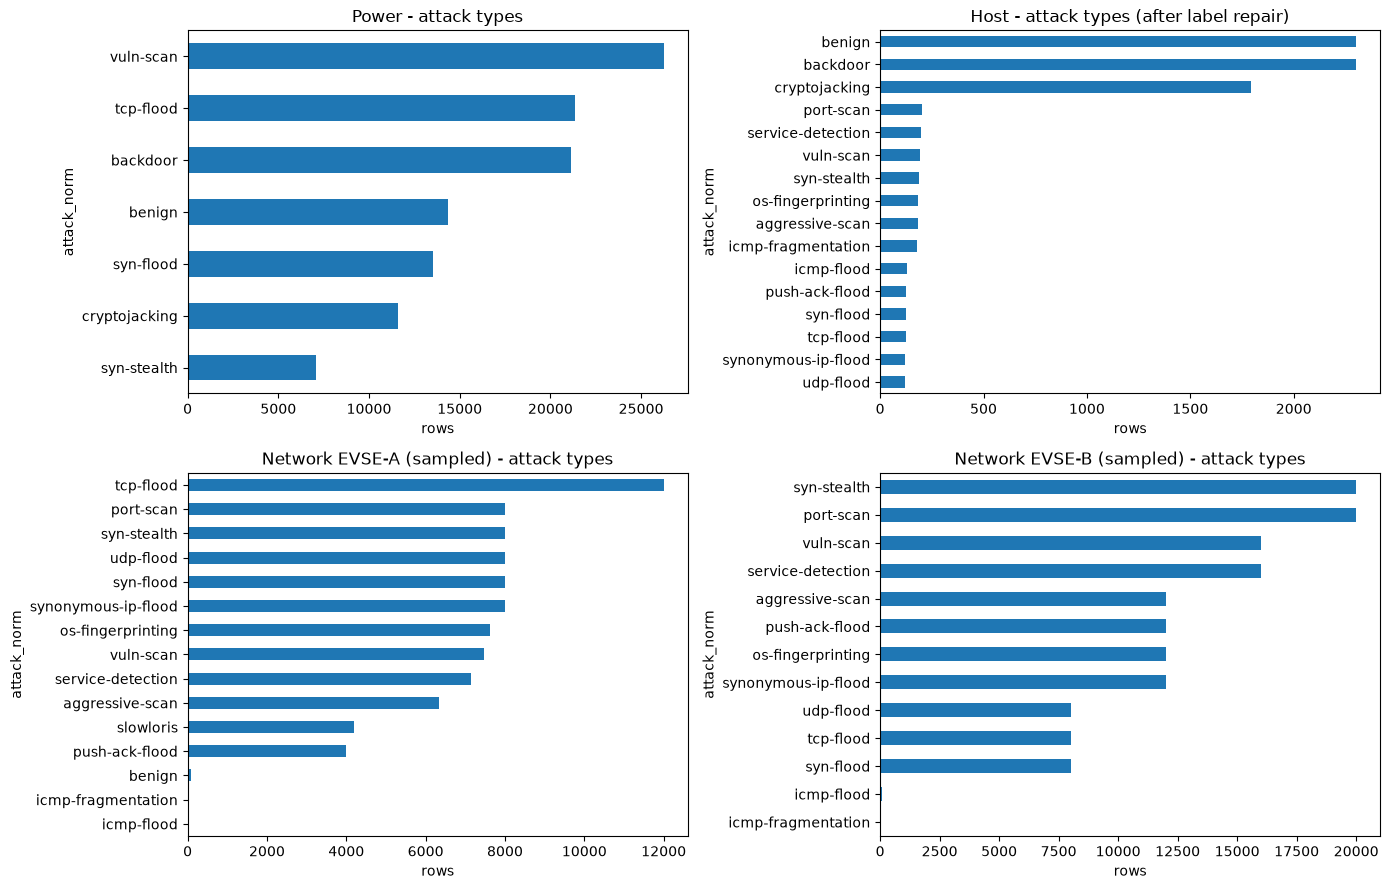

,source,rows,benign,attack
0,Power (EVSE-B),115298,14363,100935
1,Host (EVSE-B),8468,2302,6166
2,Network EVSE-A (Combined file),547854,82,547772
3,Network EVSE-B (Combined file),2196846,0,2196846


In [ ]:
def bar(ax, s, title):
    s.value_counts().sort_values().plot.barh(ax=ax)
    ax.set_title(title); ax.set_xlabel("rows")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
bar(axes[0, 0], power["attack_norm"], "Power - attack types")
bar(axes[0, 1], host["attack_norm"], "Host - attack types (after label repair)")
for ax, key, t in [(axes[1, 0], "netA", "Network EVSE-A (sampled)"), (axes[1, 1], "netB", "Network EVSE-B (sampled)")]:
    if key in net:
        bar(ax, net[key]["df"]["attack_norm"], t + " - attack types")
plt.tight_layout(); plt.savefig(RESULTS / "class_distribution.png", dpi=150); plt.show()

inv = pd.DataFrame([
    {"source": "Power (EVSE-B)", "rows": len(power), "benign": int((power.is_attack == 0).sum()), "attack": int(power.is_attack.sum())},
    {"source": "Host (EVSE-B)", "rows": len(host), "benign": int((host.is_attack == 0).sum()), "attack": int(host.is_attack.sum())},
] + [{"source": nm, "rows": net[k]["total"], "benign": int(net[k]["totals"].get("benign", 0)),
      "attack": int(net[k]["total"] - net[k]["totals"].get("benign", 0))}
     for k, nm in [("netA", "Network EVSE-A (Combined file)"), ("netB", "Network EVSE-B (Combined file)")] if k in net])
display(inv)
inv.to_csv(RESULTS / "dataset_inventory.csv", index=False)

## 6. Can the three sources be aligned in time? (decides whether cross-source correlation is legitimate)
The dataset page does not state timestamp formats or collection dates, so we check from the data.

In [ ]:
pt = pd.to_datetime(power["time"], format="%m/%d/%Y %H:%M", errors="coerce")
print("Power  :", pt.min(), "->", pt.max(), f"({pt.nunique():,} distinct minutes)")
for key in ["netA", "netB"]:
    if FILES[key].exists():
        s = pd.read_csv(FILES[key], usecols=["bidirectional_first_seen_ms"])["bidirectional_first_seen_ms"]
        t = pd.to_datetime(s, unit="ms")
        print(f"{key:7s}:", t.min(), "->", t.max(), "(epoch ms interpreted as UTC; check timezone vs power)")
ht = pd.to_numeric(host_raw["time"], errors="coerce")
print("Host   : numeric 'time' range", ht.min(), "->", ht.max(), "(looks like relative seconds, not wall-clock)")
print("Host time values that repeat (suggests it restarts per session):", int(ht.duplicated().sum()))
print("\nRead this as: overlapping date ranges between Power and Network EVSE-B = alignment may be possible;"
      " Host has no absolute time here = correlate on attack group / scenario only.")

Power  : 2023-12-24 16:18:00 -> 2023-12-30 16:20:00 (1,995 distinct minutes)
netA   : 2023-12-19 15:10:56.835000 -> 2024-01-04 20:41:59.380000 (epoch ms interpreted as UTC; check timezone vs power)
netB   : 2023-12-20 16:40:28.080000 -> 2023-12-21 20:41:17.342000 (epoch ms interpreted as UTC; check timezone vs power)
Host   : numeric 'time' range 5.0 -> 5855.669471 (looks like relative seconds, not wall-clock)
Host time values that repeat (suggests it restarts per session): 7

Read this as: overlapping date ranges between Power and Network EVSE-B = alignment may be possible; Host has no absolute time here = correlate on attack group / scenario only.


## 7. Experiment helpers - blocked split, 3 baselines, metrics, plots
**Why blocked?** Neighbouring rows (same minute / same flow burst) are near-duplicates. A random row split puts
them in both train and test and inflates scores. We split by contiguous blocks of rows instead.

In [ ]:
def blocked_split(y: pd.Series, groups, test_size=0.25, tries=60):
    """Group split by block; retry seeds so every sizeable class appears in both sets."""
    y = pd.Series(np.asarray(y)); best = None
    for i in range(tries):
        gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=SEED + i)
        tr, te = next(gss.split(np.zeros(len(y)), groups=np.asarray(groups)))
        c_tr, c_te = y.iloc[tr].value_counts(), y.iloc[te].value_counts()
        ok = all(c_tr.get(c, 0) >= 20 and c_te.get(c, 0) >= 20 for c in y.value_counts()[lambda s: s >= 100].index)
        best = (tr, te)
        if ok: return tr, te
    print("   (note: some small classes are missing from train or test in this split)")
    return best

def make_models():
    return {
        "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
        "LogisticRegression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                            LogisticRegression(max_iter=400, class_weight="balanced")),
        "RandomForest": make_pipeline(SimpleImputer(strategy="median"),
                                      RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                             n_jobs=-1, random_state=SEED)),
    }

def run_experiment(tag, X, y, groups, binary_positive=None):
    """Train/evaluate 3 baselines; save metrics, per-class report, confusion matrix, feature importance."""
    X = X.reset_index(drop=True); y = pd.Series(np.asarray(y)).astype(str)
    tr, te = blocked_split(y, groups)
    Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    print(f"\n=== {tag} | train {len(tr):,} / test {len(te):,} | classes: {sorted(y.unique())}")
    rf_fitted, rows = None, []
    for name, model in make_models().items():
        t0 = time.time(); model.fit(Xtr, ytr); t_train = time.time() - t0
        t0 = time.time(); pred = model.predict(Xte); t_inf = (time.time() - t0) / max(len(Xte), 1) * 1000
        row = {"experiment": tag, "model": name, "n_train": len(tr), "n_test": len(te),
               "accuracy": accuracy_score(yte, pred),
               "macro_F1": f1_score(yte, pred, average="macro", zero_division=0),
               "weighted_F1": f1_score(yte, pred, average="weighted", zero_division=0),
               "train_s": round(t_train, 2), "infer_ms_per_row": round(t_inf, 4)}
        if binary_positive is not None and hasattr(model, "predict_proba"):
            proba = model.predict_proba(Xte)[:, list(model.classes_).index(binary_positive)]
            yb = (yte == binary_positive).astype(int)
            if yb.nunique() == 2:
                row["ROC_AUC"] = roc_auc_score(yb, proba); row["PR_AUC"] = average_precision_score(yb, proba)
        rows.append(row); SUMMARY.append(row)
        if name == "RandomForest": rf_fitted, rf_pred = model, pred
    res = pd.DataFrame(rows).round(4); display(res)

    # per-class report + confusion matrix for the Random Forest
    rep = pd.DataFrame(classification_report(yte, rf_pred, output_dict=True, zero_division=0)).T.round(4)
    rep.to_csv(RESULTS / f"{tag}_RF_per_class.csv"); display(rep)
    labels = sorted(set(yte) | set(rf_pred))
    cm = confusion_matrix(yte, rf_pred, labels=labels, normalize="true")
    fig, ax = plt.subplots(figsize=(max(5, 0.7 * len(labels) + 3),) * 2)
    im = ax.imshow(cm, vmin=0, vmax=1, cmap="Blues"); ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=60, ha="right"); ax.set_yticklabels(labels)
    ax.set_title(f"{tag} - RF confusion matrix (row-normalised)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout()
    plt.savefig(RESULTS / f"{tag}_RF_confusion.png", dpi=150); plt.show()

    # feature importance (attribution, NOT causal proof)
    imp = pd.Series(rf_fitted[-1].feature_importances_, index=X.columns).sort_values(ascending=False)
    imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title=f"{tag} - top RF feature importances")
    plt.tight_layout(); plt.savefig(RESULTS / f"{tag}_RF_importance.png", dpi=150); plt.show()
    imp.to_csv(RESULTS / f"{tag}_RF_importance.csv")
    return {"rf": rf_fitted, "tr": tr, "te": te, "importance": imp}

## 8. Experiments
Power and Host: binary (benign vs attack) and attack-group. Network: attack-type classification only
(network files are almost entirely attack traffic, so binary detection there would be meaningless).


=== power_binary | train 86,298 / test 29,000 | classes: ['attack', 'benign']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,power_binary,Dummy (majority),86298,29000,0.8408,0.4568,0.7681,0.05,0.0000,0.5000,0.8408
1,power_binary,LogisticRegression,86298,29000,0.7799,0.6831,0.8025,0.16,0.0001,0.8002,0.9512
2,power_binary,RandomForest,86298,29000,0.9435,0.8877,0.9416,1.08,0.0021,0.9717,0.9926


,precision,recall,f1-score,support
attack,0.9539,0.9802,0.9668,24384.0000
benign,0.8775,0.7496,0.8085,4616.0000
accuracy,0.9435,0.9435,0.9435,0.9435
macro avg,0.9157,0.8649,0.8877,29000.0000
weighted avg,0.9417,0.9435,0.9416,29000.0000


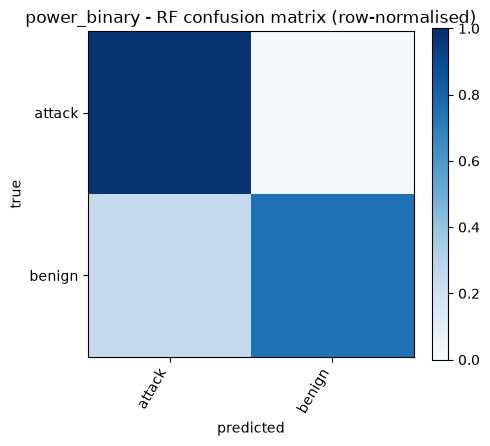

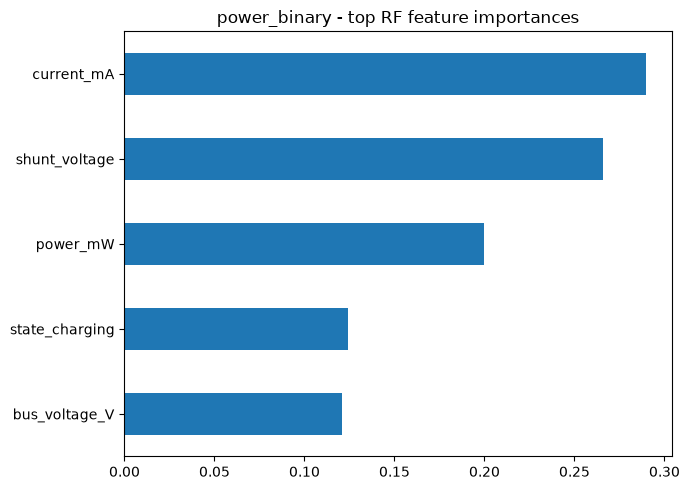


=== power_group | train 86,298 / test 29,000 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,power_group,Dummy (majority),86298,29000,0.2029,0.0843,0.0684,0.01,0.0000
1,power_group,LogisticRegression,86298,29000,0.6187,0.5858,0.6101,0.56,0.0002
2,power_group,RandomForest,86298,29000,0.6984,0.7018,0.7049,1.20,0.0030


,precision,recall,f1-score,support
DoS,0.4631,0.5702,0.5111,5884.0000
host-attack,0.8157,0.7424,0.7773,9000.0000
none,0.8660,0.7730,0.8168,4616.0000
recon,0.7041,0.6999,0.7020,9500.0000
accuracy,0.6984,0.6984,0.6984,0.6984
macro avg,0.7122,0.6964,0.7018,29000.0000
weighted avg,0.7156,0.6984,0.7049,29000.0000


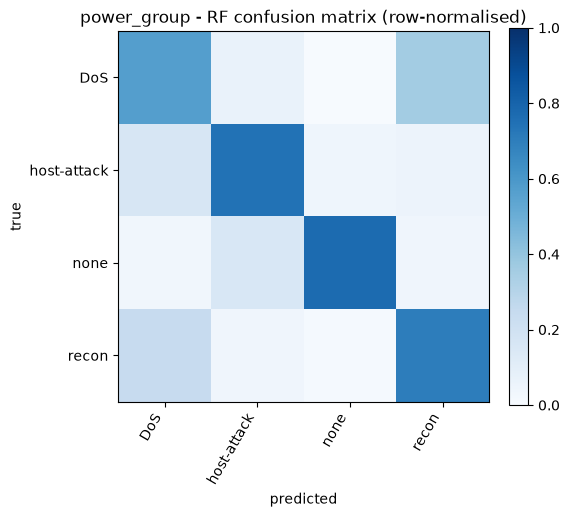

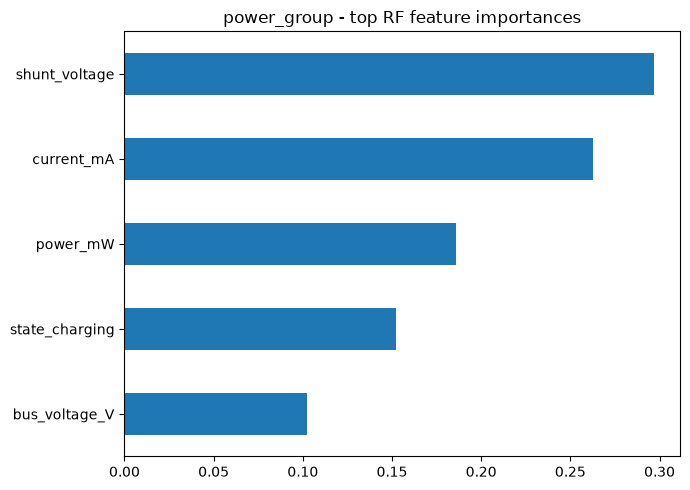

In [ ]:
Xp = power[POWER_FEATS]
pb = run_experiment("power_binary", Xp, power["is_attack"].map({0: "benign", 1: "attack"}),
                    power["row_no"] // BLOCK_ROWS["power"], binary_positive="attack")
pg = run_experiment("power_group", Xp, power["group_norm"], power["row_no"] // BLOCK_ROWS["power"])


=== host_binary | train 6,318 / test 2,150 | classes: ['attack', 'benign']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,host_binary,Dummy (majority),6318,2150,0.7209,0.4189,0.6040,0.00,0.0000,0.5000,0.7209
1,host_binary,LogisticRegression,6318,2150,0.9963,0.9954,0.9963,0.23,0.0053,0.9995,0.9998
2,host_binary,RandomForest,6318,2150,0.9972,0.9965,0.9972,0.55,0.0205,0.9999,1.0000


,precision,recall,f1-score,support
attack,0.9994,0.9968,0.9981,1550.0000
benign,0.9917,0.9983,0.9950,600.0000
accuracy,0.9972,0.9972,0.9972,0.9972
macro avg,0.9955,0.9976,0.9965,2150.0000
weighted avg,0.9972,0.9972,0.9972,2150.0000


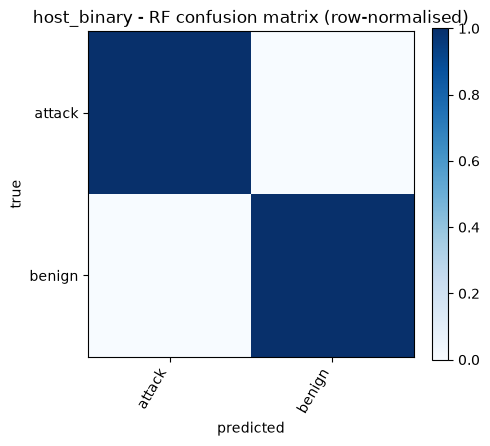

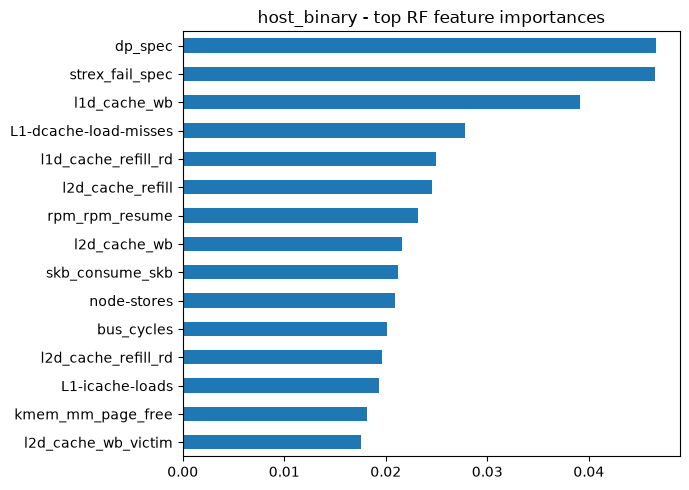


=== host_group | train 6,318 / test 2,150 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,host_group,Dummy (majority),6318,2150,0.4651,0.1587,0.2953,0.00,0.0001
1,host_group,LogisticRegression,6318,2150,0.9944,0.9899,0.9944,5.13,0.0061
2,host_group,RandomForest,6318,2150,0.9940,0.9894,0.9939,0.55,0.0262


,precision,recall,f1-score,support
DoS,1.0000,0.9539,0.9764,217.000
host-attack,1.0000,0.9990,0.9995,1000.000
none,0.9917,0.9983,0.9950,600.000
recon,0.9765,0.9970,0.9866,333.000
accuracy,0.9940,0.9940,0.9940,0.994
macro avg,0.9920,0.9871,0.9894,2150.000
weighted avg,0.9940,0.9940,0.9939,2150.000


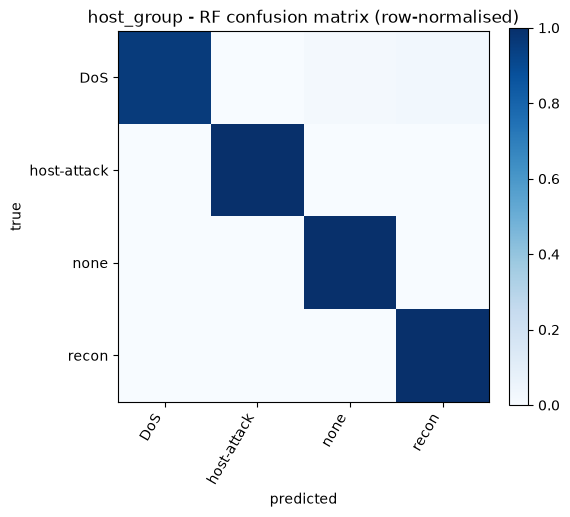

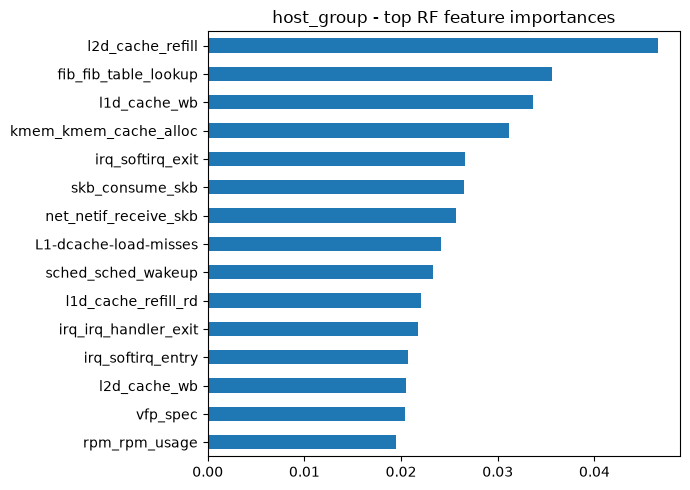

In [ ]:
hb = run_experiment("host_binary", X_host, host["is_attack"].map({0: "benign", 1: "attack"}),
                    host["row_no"] // BLOCK_ROWS["host"], binary_positive="attack")
hg = run_experiment("host_group", X_host, host["group_norm"], host["row_no"] // BLOCK_ROWS["host"])

• netA: classes with <200 sampled rows not modelled: ['benign', 'icmp-flood', 'icmp-fragmentation']

=== netA_attack_type | train 65,473 / test 23,285 | classes: ['aggressive-scan', 'os-fingerprinting', 'port-scan', 'push-ack-flood', 'service-detection', 'slowloris', 'syn-flood', 'syn-stealth', 'synonymous-ip-flood', 'tcp-flood', 'udp-flood', 'vuln-scan']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,netA_attack_type,Dummy (majority),65473,23285,0.1082,0.0163,0.0211,0.02,0.0000
1,netA_attack_type,LogisticRegression,65473,23285,0.5306,0.5357,0.5027,9.37,0.0010
2,netA_attack_type,RandomForest,65473,23285,0.5410,0.5378,0.5420,1.48,0.0056


,precision,recall,f1-score,support
aggressive-scan,0.1117,0.1740,0.1361,822.000
os-fingerprinting,0.2575,0.1778,0.2104,2519.000
port-scan,0.1707,0.1417,0.1548,2026.000
push-ack-flood,1.0000,1.0000,1.0000,1283.000
service-detection,0.0480,0.1053,0.0660,1557.000
slowloris,0.4244,0.9881,0.5938,506.000
syn-flood,0.9994,1.0000,0.9997,1596.000
syn-stealth,0.3432,0.2024,0.2547,3769.000
synonymous-ip-flood,1.0000,0.9994,0.9997,1605.000
tcp-flood,1.0000,1.0000,1.0000,2520.000


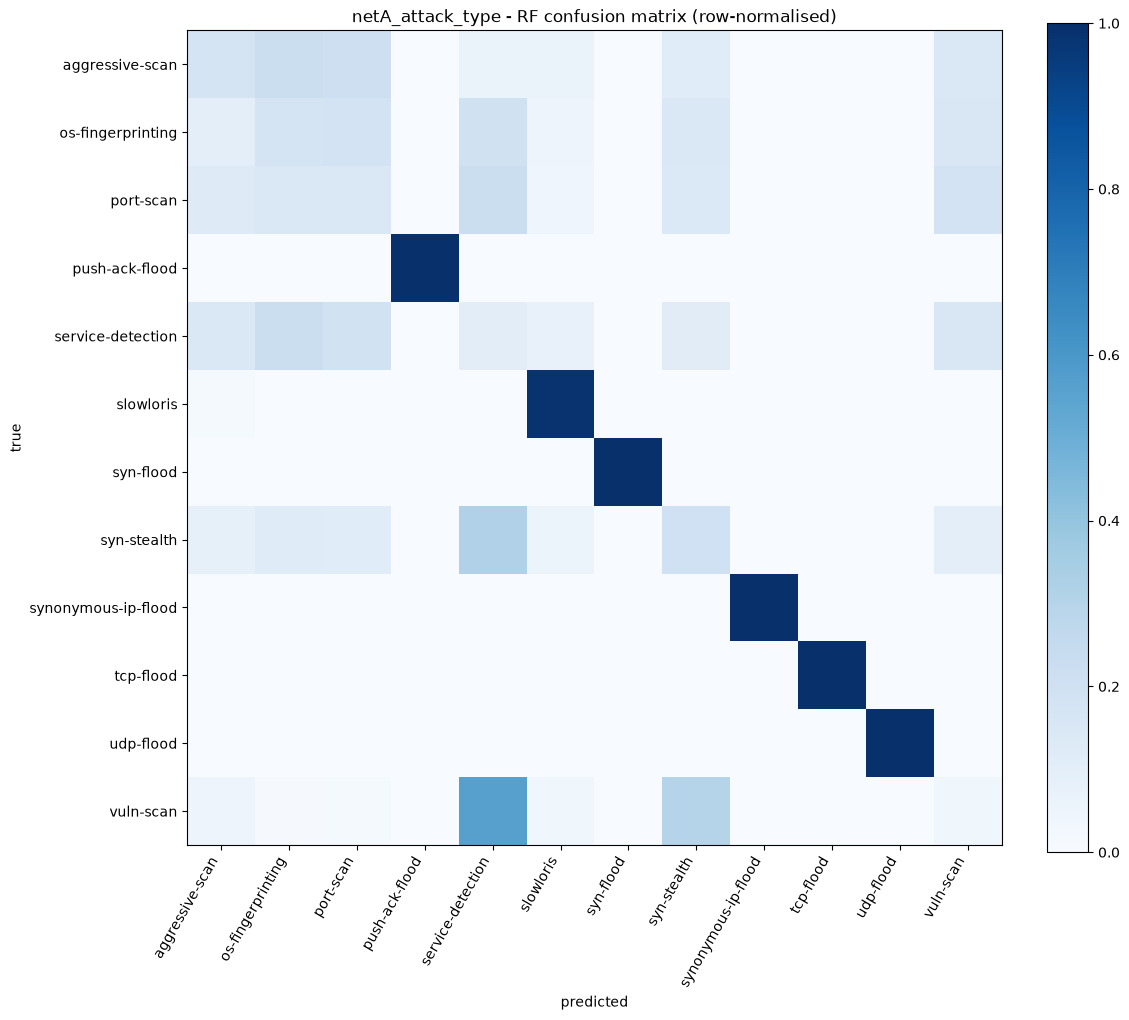

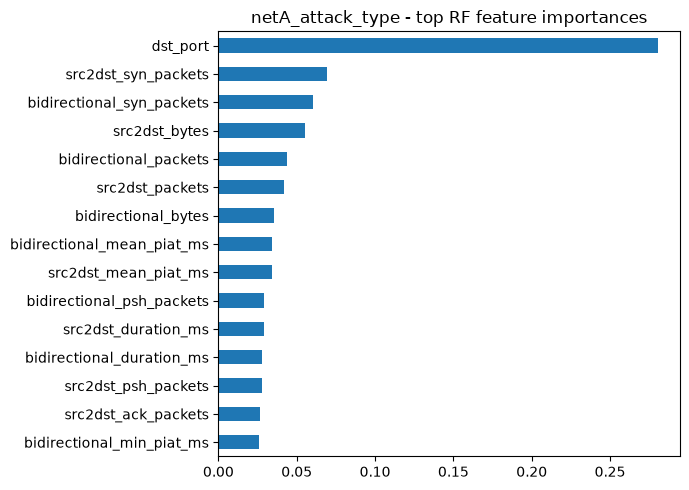

• netB: classes with <200 sampled rows not modelled: ['icmp-flood', 'icmp-fragmentation']

=== netB_attack_type | train 107,401 / test 36,599 | classes: ['aggressive-scan', 'os-fingerprinting', 'port-scan', 'push-ack-flood', 'service-detection', 'syn-flood', 'syn-stealth', 'synonymous-ip-flood', 'tcp-flood', 'udp-flood', 'vuln-scan']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,netB_attack_type,Dummy (majority),107401,36599,0.1083,0.0178,0.0212,0.02,0.0000
1,netB_attack_type,LogisticRegression,107401,36599,0.4079,0.5185,0.3908,15.19,0.0014
2,netB_attack_type,RandomForest,107401,36599,0.4301,0.5501,0.4309,2.60,0.0053


,precision,recall,f1-score,support
aggressive-scan,0.1784,0.1636,0.1707,4359.0000
os-fingerprinting,0.1221,0.1730,0.1432,2995.0000
port-scan,0.1918,0.1776,0.1844,4696.0000
push-ack-flood,1.0000,1.0000,1.0000,2517.0000
service-detection,0.2056,0.1663,0.1839,4697.0000
syn-flood,1.0000,1.0000,1.0000,1466.0000
syn-stealth,0.1586,0.2064,0.1794,3963.0000
synonymous-ip-flood,1.0000,0.9997,0.9999,3396.0000
tcp-flood,1.0000,1.0000,1.0000,1931.0000
udp-flood,0.9995,0.9990,0.9992,1971.0000


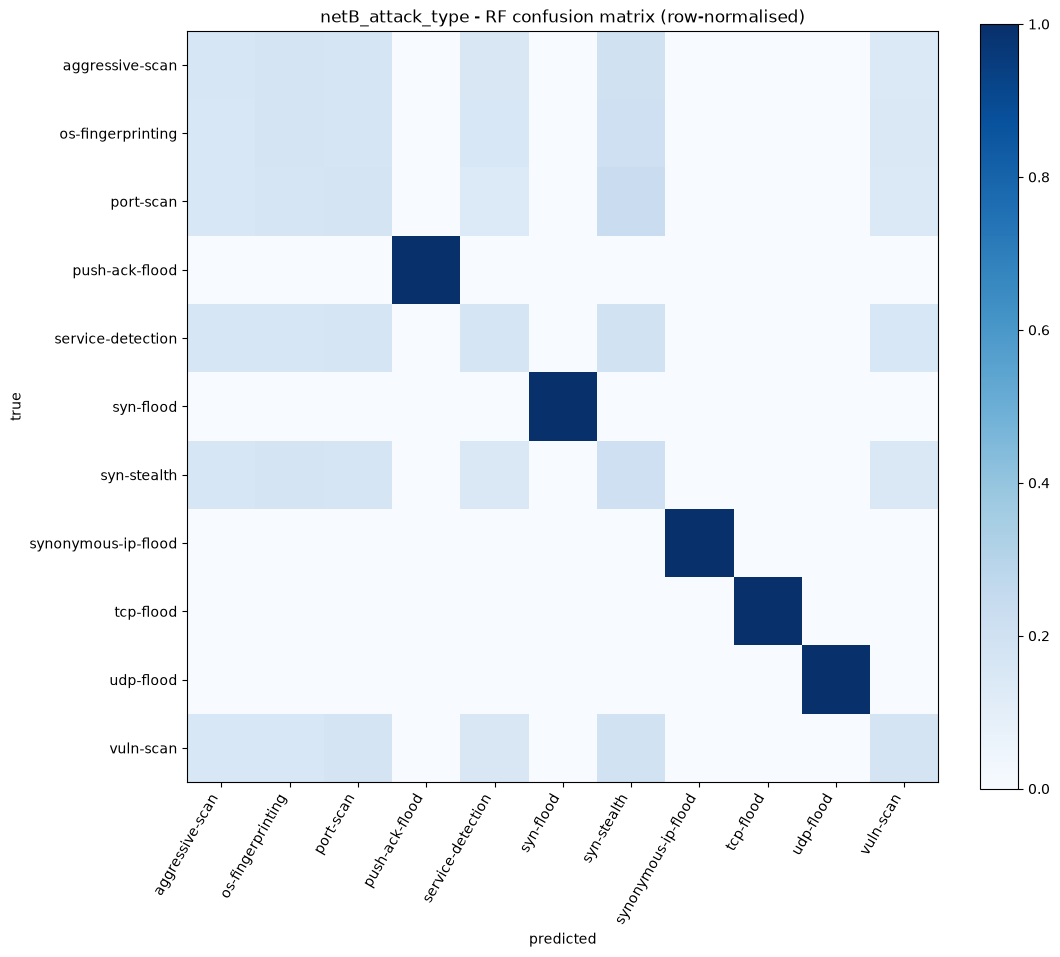

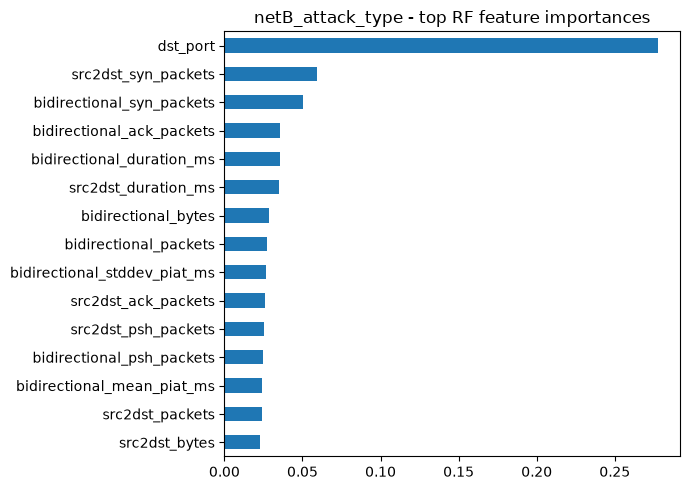

No usable EVSE-A benign flows -> network binary detection skipped.


In [ ]:
net_results = {}
for key in net:
    df, feats = net[key]["df"], net[key]["feats"]
    keep_classes = df["attack_norm"].value_counts()[lambda s: s >= MIN_CLASS_SAMPLES].index
    small = sorted(set(df["attack_norm"]) - set(keep_classes))
    if small: log(f"{key}: classes with <{MIN_CLASS_SAMPLES} sampled rows not modelled: {small}")
    d = df[df["attack_norm"].isin(keep_classes)].reset_index(drop=True)
    X = d[feats].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    net_results[key] = run_experiment(f"{key}_attack_type", X, d["attack_norm"], d["block"])

# EVSE-A benign vs attack, using the dedicated benign CSVs (EVSE-B has NO benign network files at all)
if benign_A is not None and len(benign_A) >= MIN_CLASS_SAMPLES:
    atk = net["netA"]["df"]; atk = atk[atk["attack_norm"] != "benign"]
    both = pd.concat([benign_A, atk], ignore_index=True)
    feats = [f for f in net["netA"]["feats"] if f in benign_A.columns]
    X = both[feats].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    y = np.where(both["attack_norm"] == "benign", "benign", "attack")
    net_results["netA_binary"] = run_experiment("netA_binary", X, y, both["block"], binary_positive="attack")
    print("CAUTION: benign and attack flows come from different capture files -> a model can partly learn the capture "
          "session instead of behaviour. Report this limitation.")
else:
    print("No usable EVSE-A benign flows -> network binary detection skipped.")

## 9. Separate anomaly experiment (Isolation Forest, trained on BENIGN power only)
An anomaly score is not proof of an attack - this is reported as its own experiment.

In [ ]:
tr, te = pb["tr"], pb["te"]
Xtr_b = power.iloc[tr].query("is_attack == 0")[POWER_FEATS]
scaler = StandardScaler().fit(Xtr_b)
iso = IsolationForest(n_estimators=200, contamination="auto", random_state=SEED).fit(scaler.transform(Xtr_b))
score_te = -iso.score_samples(scaler.transform(power.iloc[te][POWER_FEATS]))      # higher = more anomalous
y_te = power.iloc[te]["is_attack"].values
thr = np.percentile(-iso.score_samples(scaler.transform(Xtr_b)), 95)             # 95th pct of benign-train scores
pred = (score_te > thr).astype(int)
tp = int(((pred == 1) & (y_te == 1)).sum()); fp = int(((pred == 1) & (y_te == 0)).sum())
fn = int(((pred == 0) & (y_te == 1)).sum()); tn = int(((pred == 0) & (y_te == 0)).sum())
iso_row = {"experiment": "power_anomaly", "model": "IsolationForest(benign-only)", "n_train": len(Xtr_b), "n_test": len(te),
           "ROC_AUC": roc_auc_score(y_te, score_te), "PR_AUC": average_precision_score(y_te, score_te),
           "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "false_positive_rate": fp / max(fp + tn, 1)}
SUMMARY.append(iso_row); display(pd.DataFrame([iso_row]).round(4))
print(f"Threshold = 95th percentile of benign-train scores ({thr:.4f}); a threshold choice you must justify to the panel.")

,experiment,model,n_train,n_test,ROC_AUC,PR_AUC,precision,recall,false_positive_rate
0,power_anomaly,IsolationForest(benign-only),9747,29000,0.8292,0.9582,0.9789,0.384,0.0438


Threshold = 95th percentile of benign-train scores (0.5785); a threshold choice you must justify to the panel.


## 10. Sample structured alerts (the hand-off to the agentic layer)
Fields clearly separate **dataset observation**, **model prediction**, and **ground truth (evaluation only)**.

In [ ]:
rf, te = pb["rf"], pb["te"]
Xte = power.iloc[te]
proba = rf.predict_proba(Xte[POWER_FEATS])[:, list(rf.classes_).index("attack")]
cand_atk = np.where((Xte["is_attack"].values == 1) & (proba > 0.5))[0][:3]
cand_ben = np.where(Xte["is_attack"].values == 0)[0][:2]
top = pb["importance"].head(3)
alerts = []
for i in list(cand_atk) + list(cand_ben):
    r = Xte.iloc[i]
    alerts.append({
        "alert_id": f"ALERT-{int(r['row_no']):06d}",
        "observation": {"source": "power", "row_ref": int(r["row_no"]), "time": str(r["time"]),
                        "features": {f: float(r[f]) for f in POWER_FEATS}},
        "model_prediction": {"model": "RandomForest(power_binary)", "label": "attack" if proba[i] > 0.5 else "benign",
                             "confidence": round(float(proba[i]), 4)},
        "explanation_attribution": [{"feature": f, "global_importance": round(float(v), 4), "value": float(r[f])}
                                    for f, v in top.items()],
        "ground_truth_for_evaluation_only": {"attack": r["attack_norm"], "group": r["group_norm"]},
        "status": "needs_investigation" if proba[i] > 0.5 else "no_action",
        "note": "Feature attribution is not causal proof. Agent must retrieve evidence before claiming an incident.",
    })
(RESULTS / "alerts_demo.json").write_text(json.dumps(alerts, indent=2))
print(json.dumps(alerts[0], indent=2))

{
  "alert_id": "ALERT-004500",
  "observation": {
    "source": "power",
    "row_ref": 4500,
    "time": "12/25/2023 23:52",
    "features": {
      "shunt_voltage": 968.0,
      "bus_voltage_V": 5.165,
      "current_mA": 848.0,
      "power_mW": 4420.0,
      "state_charging": 0.0
    }
  },
  "model_prediction": {
    "model": "RandomForest(power_binary)",
    "label": "attack",
    "confidence": 1.0
  },
  "explanation_attribution": [
    {
      "feature": "current_mA",
      "global_importance": 0.2895,
      "value": 848.0
    },
    {
      "feature": "shunt_voltage",
      "global_importance": 0.2657,
      "value": 968.0
    },
    {
      "feature": "power_mW",
      "global_importance": 0.2,
      "value": 4420.0
    }
  ],
  "ground_truth_for_evaluation_only": {
    "attack": "syn-flood",
    "group": "DoS"
  },
  "status": "needs_investigation",
  "note": "Feature attribution is not causal proof. Agent must retrieve evidence before claiming an incident."
}


## 11. Optional: cross-device check (train on EVSE-A, test on EVSE-B, shared attack types only)
A stronger generalisation test than a within-device split. Expect lower scores; report them honestly.

In [ ]:
if "netA" in net and "netB" in net:
    dA, fA = net["netA"]["df"], net["netA"]["feats"]; dB, fB = net["netB"]["df"], net["netB"]["feats"]
    shared = sorted(set(dA.attack_norm) & set(dB.attack_norm))
    shared = [c for c in shared if (dA.attack_norm == c).sum() >= MIN_CLASS_SAMPLES and (dB.attack_norm == c).sum() >= MIN_CLASS_SAMPLES]
    feats = [f for f in fA if f in fB]
    a = dA[dA.attack_norm.isin(shared)]; b = dB[dB.attack_norm.isin(shared)]
    conv = lambda d: d[feats].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    m = make_models()["RandomForest"].fit(conv(a), a.attack_norm)
    p = m.predict(conv(b))
    row = {"experiment": "cross_device_A_to_B", "model": "RandomForest", "n_train": len(a), "n_test": len(b),
           "accuracy": accuracy_score(b.attack_norm, p), "macro_F1": f1_score(b.attack_norm, p, average="macro", zero_division=0),
           "weighted_F1": f1_score(b.attack_norm, p, average="weighted", zero_division=0)}
    SUMMARY.append(row); display(pd.DataFrame([row]).round(4)); print("Shared classes:", shared)

,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1
0,cross_device_A_to_B,RandomForest,84557,144000,0.3648,0.3967,0.3465


Shared classes: ['aggressive-scan', 'os-fingerprinting', 'port-scan', 'push-ack-flood', 'service-detection', 'syn-flood', 'syn-stealth', 'synonymous-ip-flood', 'tcp-flood', 'udp-flood', 'vuln-scan']


## 12. Save everything for the mentor / report

In [ ]:
summary_df = pd.DataFrame(SUMMARY).round(4)
summary_df.to_csv(RESULTS / "metrics_summary.csv", index=False)
pd.Series(CLEANING_LOG, name="cleaning_decision").to_csv(RESULTS / "cleaning_log.csv", index=False)
display(summary_df)
print("\nSaved to:", RESULTS.resolve())
print("Files:", sorted(p.name for p in RESULTS.iterdir()))

,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC,precision,recall,false_positive_rate
0,power_binary,Dummy (majority),86298,29000,0.8408,0.4568,0.7681,0.05,0.0000,0.5000,0.8408,NaN,NaN,NaN
1,power_binary,LogisticRegression,86298,29000,0.7799,0.6831,0.8025,0.16,0.0001,0.8002,0.9512,NaN,NaN,NaN
2,power_binary,RandomForest,86298,29000,0.9435,0.8877,0.9416,1.08,0.0021,0.9717,0.9926,NaN,NaN,NaN
3,power_group,Dummy (majority),86298,29000,0.2029,0.0843,0.0684,0.01,0.0000,NaN,NaN,NaN,NaN,NaN
4,power_group,LogisticRegression,86298,29000,0.6187,0.5858,0.6101,0.56,0.0002,NaN,NaN,NaN,NaN,NaN
5,power_group,RandomForest,86298,29000,0.6984,0.7018,0.7049,1.20,0.0030,NaN,NaN,NaN,NaN,NaN
6,host_binary,Dummy (majority),6318,2150,0.7209,0.4189,0.6040,0.00,0.0000,0.5000,0.7209,NaN,NaN,NaN
7,host_binary,LogisticRegression,6318,2150,0.9963,0.9954,0.9963,0.23,0.0053,0.9995,0.9998,NaN,NaN,NaN
8,host_binary,RandomForest,6318,2150,0.9972,0.9965,0.9972,0.55,0.0205,0.9999,1.0000,NaN,NaN,NaN
9,host_group,Dummy (majority),6318,2150,0.4651,0.1587,0.2953,0.00,0.0001,NaN,NaN,NaN,NaN,NaN



Saved to: E:\Dataset\extracted\preliminary_results
Files: ['alerts_demo.json', 'class_distribution.png', 'cleaning_log.csv', 'dataset_inventory.csv', 'file_inventory.csv', 'host_binary_RF_confusion.png', 'host_binary_RF_importance.csv', 'host_binary_RF_importance.png', 'host_binary_RF_per_class.csv', 'host_group_RF_confusion.png', 'host_group_RF_importance.csv', 'host_group_RF_importance.png', 'host_group_RF_per_class.csv', 'metrics_summary.csv', 'netA_attack_type_RF_confusion.png', 'netA_attack_type_RF_importance.csv', 'netA_attack_type_RF_importance.png', 'netA_attack_type_RF_per_class.csv', 'netB_attack_type_RF_confusion.png', 'netB_attack_type_RF_importance.csv', 'netB_attack_type_RF_importance.png', 'netB_attack_type_RF_per_class.csv', 'power_binary_RF_confusion.png', 'power_binary_RF_importance.csv', 'power_binary_RF_importance.png', 'power_binary_RF_per_class.csv', 'power_group_RF_confusion.png', 'power_group_RF_importance.csv', 'power_group_RF_importance.png', 'power_group_RF_